# 05 · Answering the 10 business questions
Runs `src/analytics.py` (SQL in `sql/analysis/` plus statistics in Python) and charts each answer.

> **Definitions.** *Gross value @ MSP* = production × MSP (estimate, nominal ₹). Not realised price, not farmer income. *Profit* = gross value/ha − DES cost/ha, only where official costs exist (2008-09 to 2013-14). Rainfall results are correlations.

| | |
|---|---|
| **Objective** | Answer the business questions. |
| **Dataset** | The SQLite database. |
| **Business question** | Which crops, states and markets create the most value; how do mandi prices compare with MSP (incl. 2026); did MSP beat inflation; is rainfall associated with yield? |
| **Method** | pandas aggregation, growth decomposition, CPI deflation, correlation (Pearson/Spearman), and the same questions in SQL. |
| **Output** | Tables in outputs/results/, charts in outputs/figures/. |
| **Key finding** | Value growth is mostly MSP, not volume (x4.5 nominal, x1.73 real, x1.41 volume); in Jul-Sep 2026, 91% of bajra and 63% of paddy quotes were below the new MSP. |

In [1]:
import sys, sqlite3, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import RAW, CURATED, PROC, RESULTS, FIGURES, DB_PATH, connect_ro
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
BLUE, ORANGE, AQUA, YELLOW, PINK, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#e34948", "#9aa19c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 11})
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight"); plt.show()
from src import analytics
out = analytics.main()
R = {k: v for k, v in out.items()}

analytics outputs: 33


## Q1. Which crops generate the highest estimated gross value? (avg per year, 2014-15 to 2018-19)

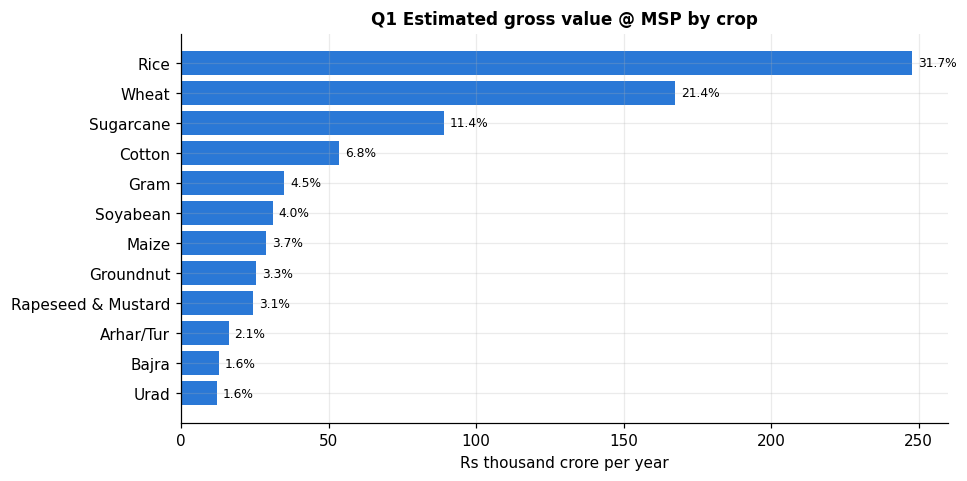

,crop_name,crop_group,avg_annual_gross_value_crore,share_of_msp_valued_pct,avg_area_mha,gross_value_per_ha
0,Rice,Cereals,247632.0,31.7,43.28,57220.0
1,Wheat,Cereals,167355.0,21.4,30.59,54708.0
2,Sugarcane,Cash crops,89151.0,11.4,4.87,183147.0
3,Cotton,Fibres,53452.0,6.8,11.98,44624.0
4,Gram,Pulses,34999.0,4.5,8.85,39530.0
5,Soyabean,Oilseeds,31050.0,4.0,10.95,28357.0
6,Maize,Cereals,28860.0,3.7,8.16,35359.0
7,Groundnut,Oilseeds,25408.0,3.3,4.41,57618.0


In [2]:
q1 = R["q01_top_revenue_crops"]
fig, ax = plt.subplots(figsize=(9, 4.6))
d = q1.head(12)[::-1]
ax.barh(d.crop_name, d.avg_annual_gross_value_crore / 1e3, color=BLUE)
for y, (v, s) in enumerate(zip(d.avg_annual_gross_value_crore / 1e3, d.share_of_msp_valued_pct)):
    ax.text(v + 2, y, f"{s}%", va="center", fontsize=8)
ax.set_xlabel("Rs thousand crore per year"); ax.set_title("Q1 Estimated gross value @ MSP by crop")
save(fig, "Q1_top_crops"); q1.head(8)

## Q2. Which crops have the highest estimated profit per hectare / acre?

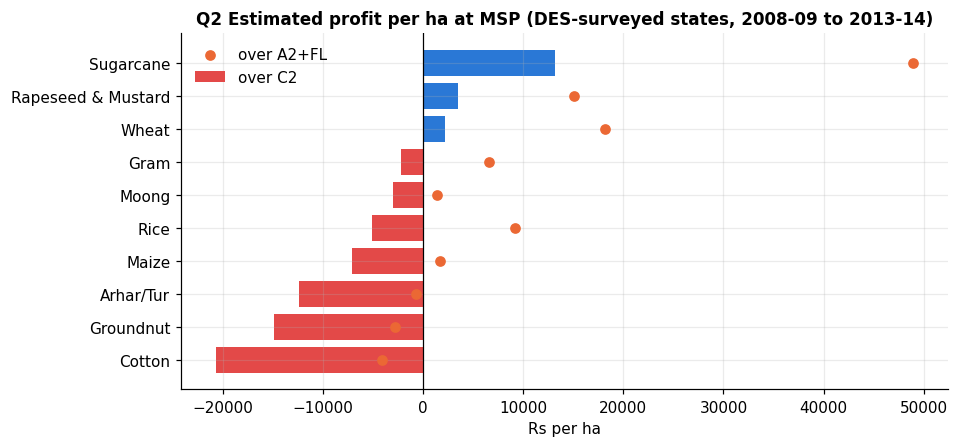

,crop_name,state_years,states,gross_value_per_ha,cost_a2fl_per_ha,cost_c2_per_ha,est_profit_a2fl_per_ha,est_profit_c2_per_ha,est_profit_c2_per_acre,pct_state_years_c2_loss,avg_apy_to_coc_yield_ratio
0,Sugarcane,30,5,108456.0,59476.0,95291.0,48979.0,13165.0,5328.0,40.0,1.04
1,Rapeseed & Mustard,29,5,31077.0,16045.0,27603.0,15032.0,3474.0,1406.0,28.0,0.85
2,Wheat,30,5,41330.0,23183.0,39160.0,18148.0,2170.0,878.0,33.0,0.78
3,Gram,29,5,22554.0,16017.0,24808.0,6537.0,-2255.0,-912.0,69.0,0.87
4,Moong,30,5,13524.0,12087.0,16570.0,1437.0,-3046.0,-1233.0,80.0,0.87
5,Rice,30,5,39743.0,30614.0,44830.0,9130.0,-5087.0,-2058.0,73.0,0.82
6,Maize,30,5,23781.0,22074.0,30860.0,1707.0,-7079.0,-2865.0,77.0,0.72
7,Arhar/Tur,30,5,22767.0,23518.0,35169.0,-751.0,-12403.0,-5019.0,73.0,0.80
8,Groundnut,30,5,27807.0,30628.0,42724.0,-2820.0,-14917.0,-6037.0,70.0,0.87
9,Cotton,30,5,35388.0,39451.0,56081.0,-4063.0,-20693.0,-8374.0,90.0,0.80


In [3]:
q2 = R["q02_profit_per_ha"]
fig, ax = plt.subplots(figsize=(9, 4.2))
d = q2.sort_values("est_profit_c2_per_ha")
ax.barh(d.crop_name, d.est_profit_c2_per_ha, color=[RED if v < 0 else BLUE for v in d.est_profit_c2_per_ha], label="over C2")
ax.scatter(d.est_profit_a2fl_per_ha, d.crop_name, color=ORANGE, zorder=3, label="over A2+FL")
ax.axvline(0, color="k", lw=.8); ax.legend(frameon=False)
ax.set_title("Q2 Estimated profit per ha at MSP (DES-surveyed states, 2008-09 to 2013-14)"); ax.set_xlabel("Rs per ha")
save(fig, "Q2_profit"); q2

Positive over A2+FL (paid-out cost + family labour) for most crops, but negative over C2 (which adds imputed rent and interest) for rice, maize, pulses, groundnut and cotton. **Caveat:** valuing at MSP understates crops sold above MSP. Maharashtra tur traded 32–88% above MSP in 2014-16.

## Q3. Which states and districts have stronger crop economics?

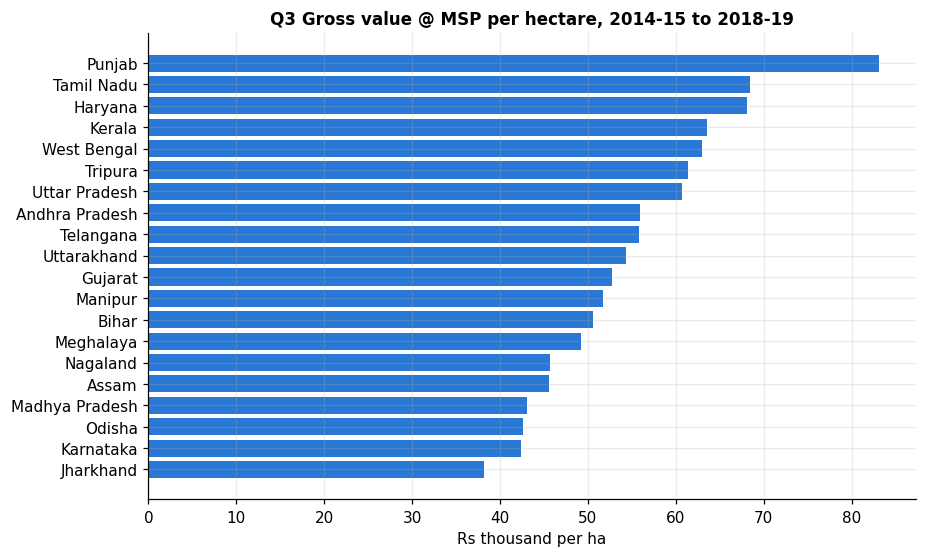

,state_name,region,avg_annual_gross_value_crore,avg_valued_area_mha,gross_value_per_ha,n_crops
0,Punjab,North,52481.0,6.31,83126.0,16
1,Tamil Nadu,South,22531.0,3.29,68444.0,16
2,Haryana,North,37672.0,5.53,68087.0,17
3,Kerala,South,1232.0,0.19,63598.0,12
4,West Bengal,East,46710.0,7.42,62927.0,22
5,Tripura,North-East,1925.0,0.31,61387.0,16
6,Uttar Pradesh,North,138603.0,22.85,60662.0,18
7,Andhra Pradesh,South,27570.0,4.93,55963.0,19
8,Telangana,South,27068.0,4.85,55778.0,19
9,Uttarakhand,North,4814.0,0.89,54278.0,18


,state_name,district_name,gross_value_per_ha,avg_annual_gross_value_crore,avg_valued_area_ha
0,Uttar Pradesh,Muzaffarnagar,146125.0,3972.0,271813.0
1,Uttar Pradesh,Meerut,146115.0,3332.0,228025.0
2,Uttar Pradesh,Baghpat,135341.0,1878.0,138725.0
3,Uttar Pradesh,Shamli,133049.0,1816.0,136489.0
4,Uttar Pradesh,Bijnor,122756.0,4906.0,399694.0
5,Maharashtra,Kolhapur,121840.0,4651.0,381707.0
6,Tamil Nadu,Erode,116253.0,702.0,60409.0
7,Tamil Nadu,Villupuram,108562.0,3280.0,302159.0
8,Uttar Pradesh,Ghaziabad,107314.0,633.0,59025.0
9,Gujarat,Surat,106942.0,1856.0,173509.0


In [4]:
q3 = R["q03_state_economics"]
fig, ax = plt.subplots(figsize=(9, 5.5))
d = q3.head(20)[::-1]
ax.barh(d.state_name, d.gross_value_per_ha / 1e3, color=BLUE)
ax.set_xlabel("Rs thousand per ha"); ax.set_title("Q3 Gross value @ MSP per hectare, 2014-15 to 2018-19")
save(fig, "Q3_states"); display(q3.head(10)); R["q03b_district_top"].head(10)

## Q4. How does yield affect estimated revenue?

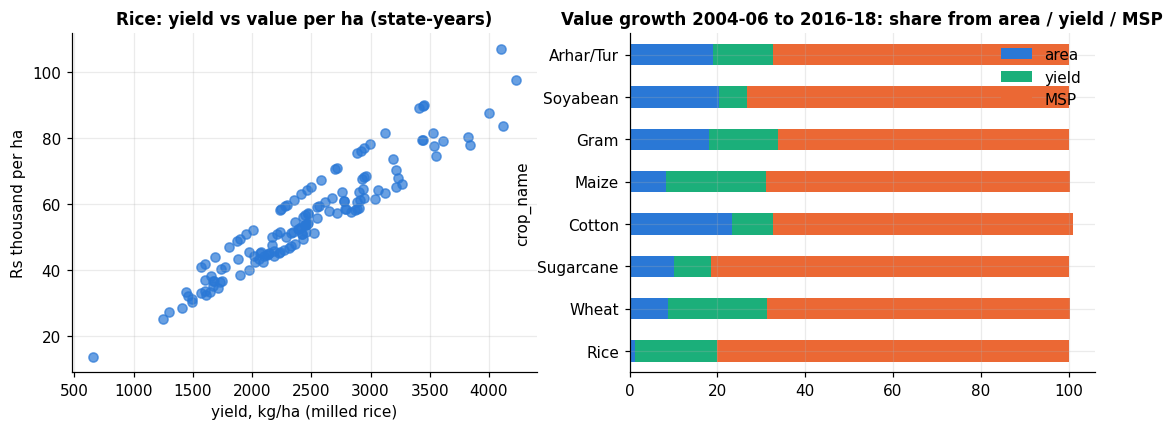

,crop_name,district_years,bottom_quartile_yield_kg_ha,top_quartile_yield_kg_ha,bottom_quartile_value_per_ha,top_quartile_value_per_ha,value_gap_per_ha,value_per_ha_ratio
18,Sugarcane,1147,42891,95000,101200,234600,133400,2.32
5,Groundnut,1006,754,2216,31650,96745,65095,3.06
3,Cotton,881,162,647,18208,77887,59680,4.28
7,Jute,183,1157,2947,34778,91596,56817,2.63
19,Sunflower,184,284,1459,10947,61717,50769,5.64
0,Arhar/Tur,1140,372,1269,17700,67333,49633,3.80
14,Rice,2908,1286,3374,28687,77558,48871,2.70
21,Wheat,1987,1330,4206,21362,70119,48758,3.28
4,Gram,1184,596,1441,21116,62734,41618,2.97
13,Rapeseed & Mustard,1547,538,1503,19155,57000,37845,2.98


In [5]:
con = connect_ro()
s = pd.read_sql("""select state_name, crop_year, yield_kg_per_ha, gross_value_msp_per_ha from fact_state_crop_year
                   where crop_name='Rice' and crop_year between 2014 and 2018 and gross_value_msp_inr is not null and area_ha>20000""", con)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(s.yield_kg_per_ha, s.gross_value_msp_per_ha / 1e3, color=BLUE, alpha=.7)
axes[0].set_xlabel("yield, kg/ha (milled rice)"); axes[0].set_ylabel("Rs thousand per ha"); axes[0].set_title("Rice: yield vs value per ha (state-years)")
d = R["q04b_value_growth_decomposition"].set_index("crop_name").loc[["Rice", "Wheat", "Sugarcane", "Cotton", "Maize", "Gram", "Soyabean", "Arhar/Tur"]]
d[["area_contribution_pct", "yield_contribution_pct", "price_msp_contribution_pct"]].plot.barh(stacked=True, ax=axes[1], color=[BLUE, AQUA, ORANGE])
axes[1].set_title("Value growth 2004-06 to 2016-18: share from area / yield / MSP"); axes[1].legend(["area", "yield", "MSP"], frameon=False)
save(fig, "Q4_yield"); R["q04a_yield_quartile_value_gap"].head(10)

At a single MSP, value per hectare moves one-for-one with yield: top-quartile-yield districts earn 2.3–5.6× the value/ha of bottom-quartile ones. Over time, though, most value growth came from MSP increases, not yield.

## Q5. How do mandi prices differ across markets?
Recent window first (daily cross-market CV, Jul–Sep 2026), then the 30-Sep-2024 snapshot.

In [6]:
R["q11c_dispersion_2026"][["crop_name", "price_form", "markets", "median_daily_cross_market_cv_pct", "median", "cheapest_state", "cheapest_state_median", "dearest_state", "dearest_state_median"]].head(12)

,crop_name,price_form,markets,median_daily_cross_market_cv_pct,median,cheapest_state,cheapest_state_median,dearest_state,dearest_state_median
10,Potato,Potato,924,68.3,1800.0,Uttar Pradesh,600.00,Tamil Nadu,3300.0
12,Rice,Milled rice,247,38.5,3800.0,Uttar Pradesh,2600.00,Assam,7500.0
5,Jowar,Jowar (mixed varieties),166,37.8,3728.0,Karnataka,2600.00,Gujarat,5882.5
9,Onion,Onion,921,29.6,3900.0,Uttar Pradesh,2100.00,Manipur,5750.0
16,Urad,Urad (whole),169,23.3,8300.0,Rajasthan,6876.00,Kerala,13300.0
6,Maize,Maize,470,22.9,2300.0,Uttarakhand,1500.00,West Bengal,2550.0
8,Moong,Moong (whole),309,20.9,7230.0,Rajasthan,6690.00,Kerala,12300.0
7,Masoor,Masur (whole),75,20.1,6755.5,Madhya Pradesh,6400.00,Assam,8700.0
13,Rice,Paddy (common),535,19.2,2390.0,Chhattisgarh,2000.00,Maharashtra,3143.0
0,Arhar/Tur,Tur (whole),225,18.7,7589.5,Gujarat,6732.50,Kerala,12600.0


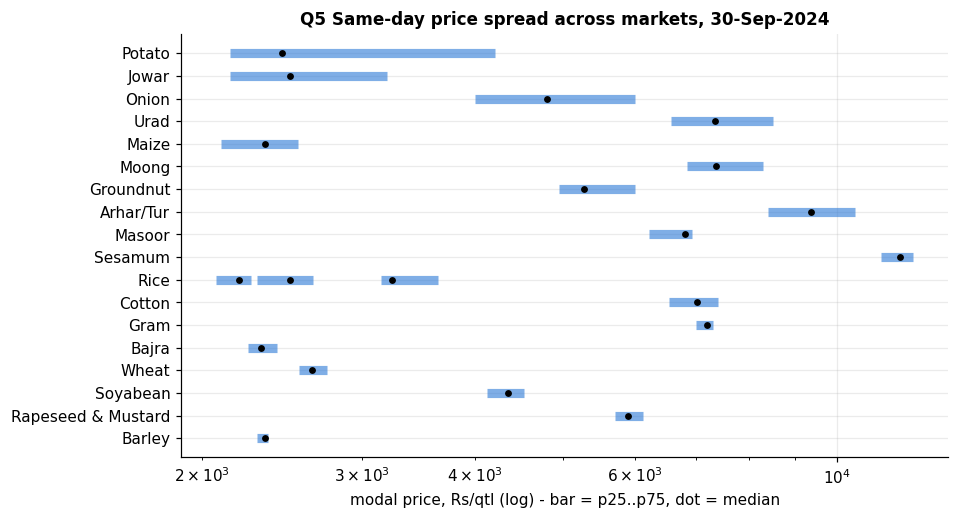

,crop_name,n_markets,median,cv_pct,cheapest_state,dearest_state
12,Potato,543,2450.0,44.5,Uttarakhand,Nagaland
7,Jowar,39,2500.0,27.2,Maharashtra,Gujarat
11,Onion,561,4800.0,25.5,Uttarakhand,Tamil Nadu
19,Urad,74,7352.5,21.4,Karnataka,Kerala
8,Maize,171,2349.0,20.4,Madhya Pradesh,Tamil Nadu
10,Moong,59,7370.0,19.5,Rajasthan,Kerala
14,Rice,162,3237.5,18.2,Uttar Pradesh,Kerala
6,Groundnut,100,5266.0,17.9,Karnataka,Andhra Pradesh
0,Arhar/Tur,33,9375.0,16.8,Telangana,Kerala
9,Masoor,42,6810.0,15.1,Rajasthan,West Bengal


In [7]:
q5 = R["q05a_cross_market_dispersion_2024"]
d = q5[~q5.price_form.str.contains(" - ")].sort_values("cv_pct")
fig, ax = plt.subplots(figsize=(9, 5))
ax.hlines(d.crop_name, d.p25, d.p75, color=BLUE, lw=6, alpha=.6); ax.scatter(d["median"], d.crop_name, color="k", s=12, zorder=3)
ax.set_xscale("log"); ax.set_xlabel("modal price, Rs/qtl (log) - bar = p25..p75, dot = median")
ax.set_title("Q5 Same-day price spread across markets, 30-Sep-2024")
save(fig, "Q5_dispersion"); d[["crop_name", "n_markets", "median", "cv_pct", "cheapest_state", "dearest_state"]].sort_values("cv_pct", ascending=False)

## Q6. Modal mandi price vs MSP (comparable commodity forms only)
Most recent window: AGMARKNET daily, 21-Jul to 24-Sep-2026 (kharif crops vs KMS 2025-26 MSP, rabi crops vs RMS 2026-27).

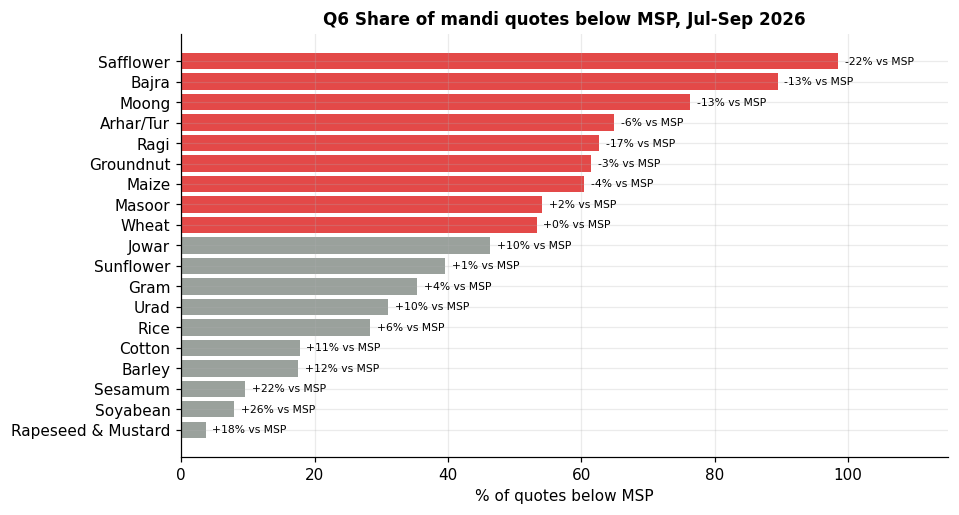

month,2026-07,2026-08,2026-09
crop_name,,,
Arhar/Tur,75.1,72.6,47.8
Bajra,89.9,92.0,86.5
Moong,86.9,74.9,70.4
Soyabean,1.2,2.8,19.3
Wheat,68.6,56.1,37.5


,crop_name,price_form,quotes,markets,states,msp,median_modal,pct_quotes_below_msp,avg_modal_vs_msp_pct
14,Safflower,Safflower,65,21,5,6540.0,5215.0,98.5,-22.0
1,Bajra,Bajra,1137,199,9,2775.0,2337.0,89.4,-13.2
9,Moong,Moong (whole),1686,309,12,8768.0,7230.0,76.3,-12.9
0,Arhar/Tur,Tur (whole),1060,225,11,8000.0,7589.5,64.9,-6.0
11,Ragi,Ragi,244,38,6,4886.0,3592.8,62.7,-16.8
5,Groundnut,Groundnut in shell,3010,214,13,7263.0,7000.0,61.5,-3.1
7,Maize,Maize,3460,470,19,2400.0,2300.0,60.4,-4.5
8,Masoor,Masur (whole),518,75,6,7000.0,6755.5,54.1,1.7
19,Wheat,Wheat grain,8759,819,12,2585.0,2570.0,53.3,0.4
6,Jowar,Jowar (mixed varieties),851,166,10,3699.0,3728.0,46.3,10.1


In [8]:
q6r = R["q11a_msp_gap_2026"].sort_values("pct_quotes_below_msp")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(q6r.crop_name, q6r.pct_quotes_below_msp, color=[RED if v >= 50 else GREY for v in q6r.pct_quotes_below_msp])
for y, (v, g) in enumerate(zip(q6r.pct_quotes_below_msp, q6r.avg_modal_vs_msp_pct)):
    ax.text(v + 1, y, f"{g:+.0f}% vs MSP", va="center", fontsize=7)
ax.set_xlim(0, 115); ax.set_xlabel("% of quotes below MSP"); ax.set_title("Q6 Share of mandi quotes below MSP, Jul-Sep 2026")
save(fig, "Q6_below_msp_2026")
m = R["q11b_msp_gap_by_month_2026"]
display(m[m.crop_name.isin(["Arhar/Tur", "Bajra", "Moong", "Wheat", "Soyabean"])].pivot(index="crop_name", columns="month", values="pct_below_msp"))
q6r.sort_values("pct_quotes_below_msp", ascending=False)

### 2026 season outlook
MSPs for the 2026 season were announced on 13-May-2026 (KMS 2026-27, PIB) and 30-Sep-2026 (RMS 2027-28). They apply from Oct-2026 (kharif) and Apr-2027 (rabi), so the Jul-Sep 2026 prices are compared with them as a forward benchmark. Harvest-time prices are not yet observed.

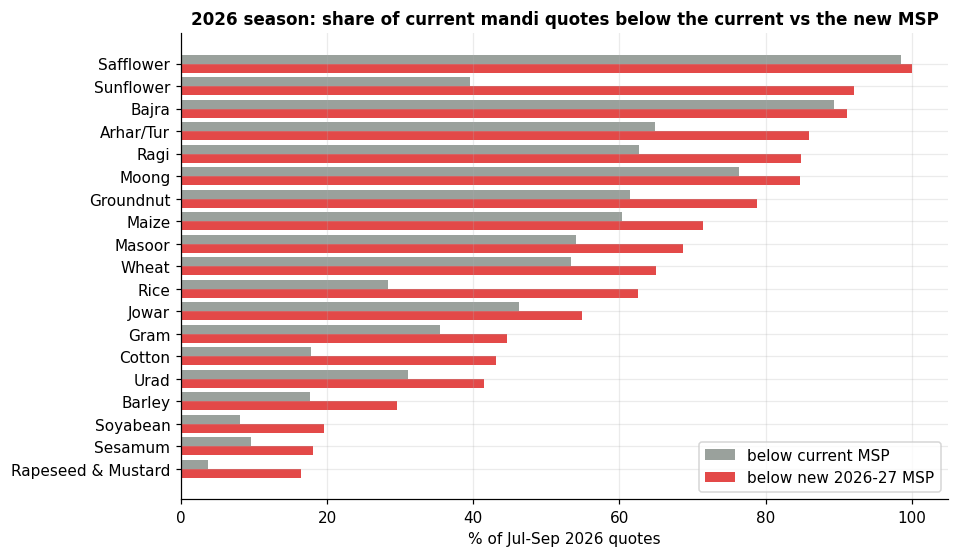

,msp_key,season,crop_year_label,msp_effective,a2fl_cost,msp_over_a2fl_pct,source_id,msp_prev,hike_pct
13,Safflower,Rabi,2026-27,7215.0,NaN,NaN,NEWS_RB_2027,6540.0,10.3
5,Jowar,Kharif,2026-27,4023.0,2682.0,50.0,PIB_KH_2026,3699.0,8.8
16,Sunflower,Kharif,2026-27,8343.0,5562.0,50.0,PIB_KH_2026,7721.0,8.1
2,Cotton,Kharif,2026-27,8267.0,5511.0,50.0,PIB_KH_2026,7710.0,7.2
15,Soyabean,Kharif,2026-27,5708.0,3805.0,50.0,PIB_KH_2026,5328.0,7.1
9,Mustard,Rabi,2026-27,6613.0,NaN,NaN,NEWS_RB_2027,6200.0,6.7
12,Ragi,Kharif,2026-27,5205.0,3470.0,50.0,PIB_KH_2026,4886.0,6.5
1,Barley,Rabi,2026-27,2286.0,NaN,NaN,NEWS_RB_2027,2150.0,6.3
7,Masur,Rabi,2026-27,7390.0,NaN,NaN,NEWS_RB_2027,7000.0,5.6
17,Tur,Kharif,2026-27,8450.0,5496.0,53.7,PIB_KH_2026,8000.0,5.6


,crop_name,price_form,quotes,msp_current,msp_next,msp_hike_pct,median_modal,pct_below_current_msp,pct_below_next_msp
14,Safflower,Safflower,65,6540.0,7215.0,10.3,5215.0,98.5,100.0
17,Sunflower,Sunflower seed,139,7721.0,8343.0,8.1,7900.0,39.6,92.1
1,Bajra,Bajra,1137,2775.0,2900.0,4.5,2337.0,89.4,91.1
0,Arhar/Tur,Tur (whole),1060,8000.0,8450.0,5.6,7589.5,64.9,86.0
11,Ragi,Ragi,244,4886.0,5205.0,6.5,3592.8,62.7,84.8
9,Moong,Moong (whole),1686,8768.0,8780.0,0.1,7230.0,76.3,84.7
5,Groundnut,Groundnut in shell,3010,7263.0,7517.0,3.5,7000.0,61.5,78.8
7,Maize,Maize,3460,2400.0,2410.0,0.4,2300.0,60.4,71.4
8,Masoor,Masur (whole),518,7000.0,7390.0,5.6,6755.5,54.1,68.7
19,Wheat,Wheat grain,8759,2585.0,2610.0,1.0,2570.0,53.3,65.0


In [9]:
o = R["q11g_season_2026_outlook"].sort_values("pct_below_next_msp")
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(o))
ax.barh(y + .2, o.pct_below_current_msp, .4, color=GREY, label="below current MSP")
ax.barh(y - .2, o.pct_below_next_msp, .4, color=RED, label="below new 2026-27 MSP")
ax.set_yticks(y, o.crop_name); ax.set_xlim(0, 105); ax.legend(loc="lower right")
ax.set_xlabel("% of Jul-Sep 2026 quotes"); ax.set_title("2026 season: share of current mandi quotes below the current vs the new MSP")
save(fig, "Q6_season_2026_outlook")
display(R["q11h_msp_2026_27_vs_cost"])
o.sort_values("pct_below_next_msp", ascending=False)[["crop_name", "price_form", "quotes", "msp_current", "msp_next", "msp_hike_pct",
    "median_modal", "pct_below_current_msp", "pct_below_next_msp"]]

Earlier windows for comparison: the 30-Sep-2024 snapshot and Maharashtra 2014-16.

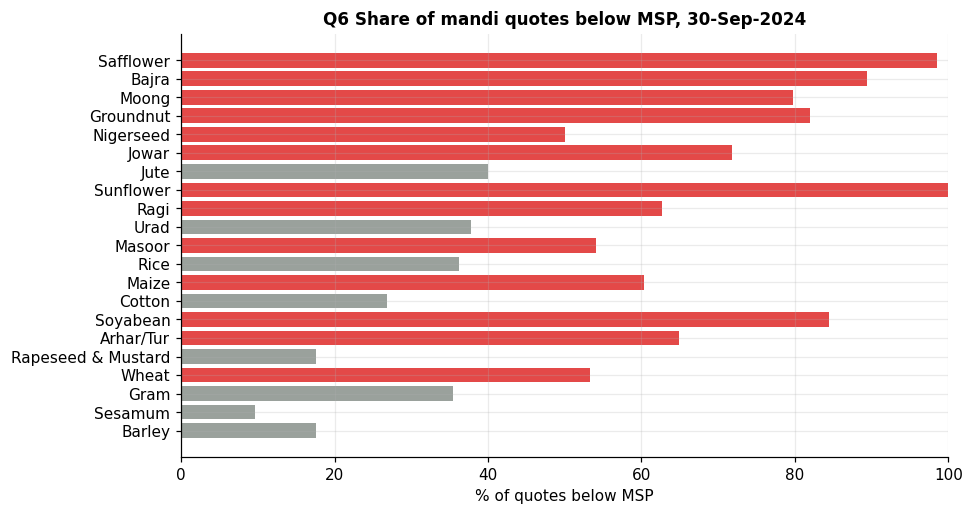

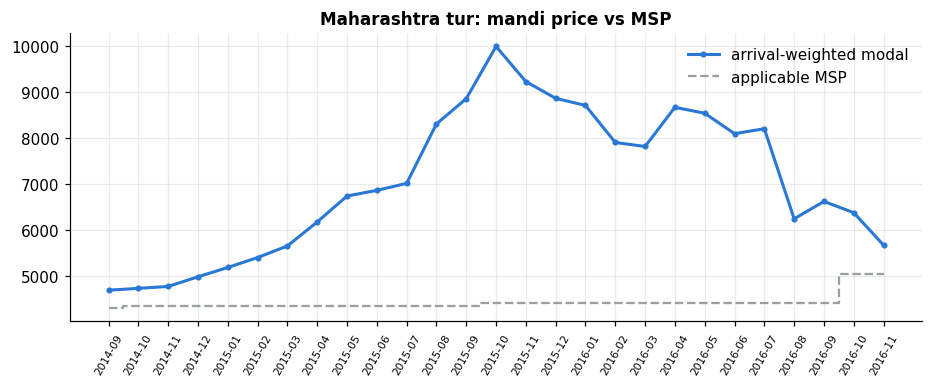

,source_dataset,crop_name,price_form,n_quotes,avg_msp,avg_modal,pct_quotes_below_msp,avg_modal_vs_msp_pct
0,AGMARKNET daily Jul-Sep 2026,Safflower,Safflower,65,6540.0,5101.0,98.5,-22.0
1,AGMARKNET daily Jul-Sep 2026,Bajra,Bajra,1137,2775.0,2409.0,89.4,-13.2
2,AGMARKNET daily Jul-Sep 2026,Moong,Moong (whole),1686,8768.0,7641.0,76.3,-12.9
3,AGMARKNET daily Jul-Sep 2026,Arhar/Tur,Tur (whole),1060,8000.0,7523.0,64.9,-6.0
4,AGMARKNET daily Jul-Sep 2026,Ragi,Ragi,244,4886.0,4063.0,62.7,-16.8
5,AGMARKNET daily Jul-Sep 2026,Groundnut,Groundnut in shell,3010,7263.0,7037.0,61.5,-3.1
6,AGMARKNET daily Jul-Sep 2026,Maize,Maize,3460,2400.0,2292.0,60.4,-4.5
7,AGMARKNET daily Jul-Sep 2026,Masoor,Masur (whole),518,7000.0,7118.0,54.1,1.7
8,AGMARKNET daily Jul-Sep 2026,Wheat,Wheat grain,8759,2585.0,2594.0,53.3,0.4
9,AGMARKNET daily Jul-Sep 2026,Nigerseed,Nigerseed,6,9537.0,8617.0,50.0,-9.7


In [10]:
q6 = R["q06_mandi_vs_msp"]
snap = q6[q6.source_dataset.str.startswith("AGMARKNET")].sort_values("pct_quotes_below_msp")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(snap.crop_name, snap.pct_quotes_below_msp, color=[RED if v >= 50 else GREY for v in snap.pct_quotes_below_msp])
ax.set_xlim(0, 100); ax.set_xlabel("% of quotes below MSP"); ax.set_title("Q6 Share of mandi quotes below MSP, 30-Sep-2024")
save(fig, "Q6_below_msp")
mh = R["q06b_mh_monthly_msp_gap"]; t = mh[mh.crop_name == "Arhar/Tur"]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t.year_month, t.awm_modal, color=BLUE, lw=2, marker="o", ms=3, label="arrival-weighted modal")
ax.step(t.year_month, t.msp, color=GREY, ls="--", where="mid", label="applicable MSP")
ax.set_title("Maharashtra tur: mandi price vs MSP"); ax.legend(frameon=False); ax.tick_params(axis="x", rotation=60, labelsize=7)
save(fig, "Q6_tur_mh"); q6.head(12)

## Q7. How does rainfall relate to crop yield? (association only)

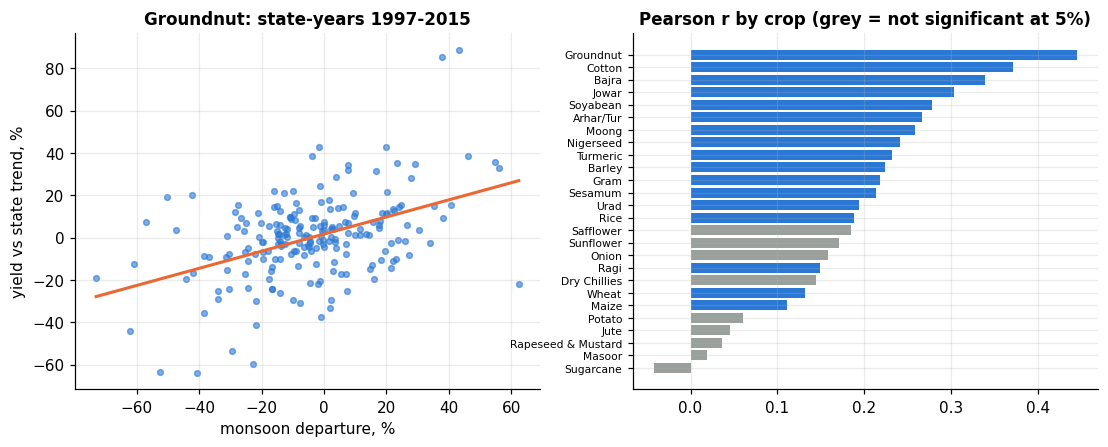

,crop_name,n_state_years,pearson_r,pearson_p,yield_anomaly_pp_per_10pct_rain,significant_5pct
6,Groundnut,203,0.445,0.0000,4.04,yes
3,Cotton,168,0.371,0.0000,4.69,yes
1,Bajra,182,0.339,0.0000,2.80,yes
7,Jowar,168,0.304,0.0001,2.59,yes
20,Soyabean,138,0.278,0.0010,3.95,yes
0,Arhar/Tur,212,0.267,0.0001,2.28,yes
11,Moong,244,0.259,0.0000,2.90,yes
12,Nigerseed,104,0.241,0.0136,2.57,yes
23,Turmeric,80,0.232,0.0380,2.32,yes
2,Barley,138,0.224,0.0082,0.47,yes


In [11]:
q7 = R["q07a_rain_yield_association"]
scy = pd.read_sql("select crop_name, season_rain_dep_pct, yield_anomaly_pct from fact_state_crop_year where yield_anomaly_pct is not null and season_rain_dep_pct is not null", con)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
g = scy[scy.crop_name == "Groundnut"]
axes[0].scatter(g.season_rain_dep_pct, g.yield_anomaly_pct, color=BLUE, alpha=.6, s=14)
b, a = np.polyfit(g.season_rain_dep_pct, g.yield_anomaly_pct, 1); xs = np.linspace(g.season_rain_dep_pct.min(), g.season_rain_dep_pct.max(), 2)
axes[0].plot(xs, a + b * xs, color=ORANGE, lw=2)
axes[0].set_xlabel("monsoon departure, %"); axes[0].set_ylabel("yield vs state trend, %"); axes[0].set_title("Groundnut: state-years 1997-2015")
d = q7.sort_values("pearson_r")
axes[1].barh(d.crop_name, d.pearson_r, color=[BLUE if s == "yes" else GREY for s in d.significant_5pct])
axes[1].set_title("Pearson r by crop (grey = not significant at 5%)"); axes[1].tick_params(axis="y", labelsize=7)
save(fig, "Q7_rain_yield"); q7[["crop_name", "n_state_years", "pearson_r", "pearson_p", "yield_anomaly_pp_per_10pct_rain", "significant_5pct"]]

Rainfed kharif crops (groundnut, cotton, bajra, jowar, soyabean) show clear positive associations. Irrigated wheat and sugarcane barely respond. **This is not causal.** Irrigation, prices, pests and sown area are not controlled for.

## Q8. High production but low profitability

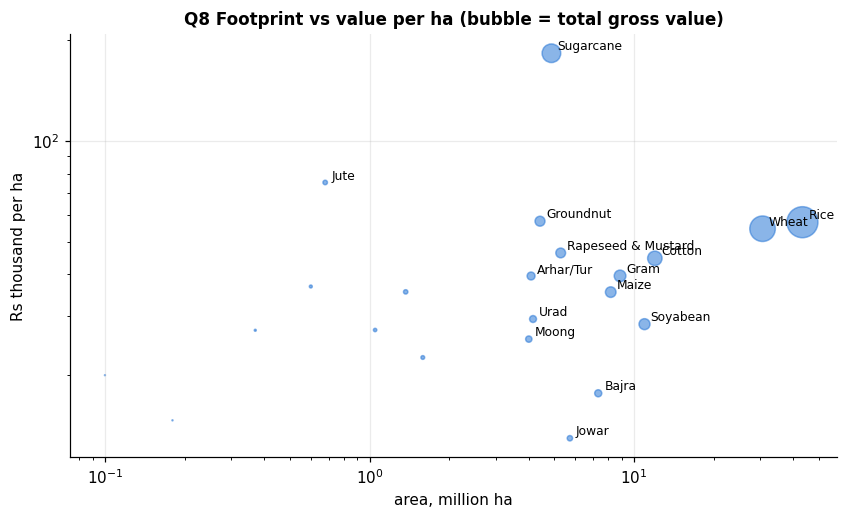

,crop_name,avg_area_mha,gross_value_per_ha,est_profit_c2_per_ha,pct_state_years_c2_loss,quadrant
0,Rice,43.28,57220.0,-5087.0,73.0,"Large footprint, high value/ha"
1,Wheat,30.59,54708.0,2170.0,33.0,"Large footprint, high value/ha"
3,Cotton,11.98,44624.0,-20693.0,90.0,"Large footprint, high value/ha"
5,Soyabean,10.95,28357.0,NaN,NaN,"Large footprint, low value/ha"
4,Gram,8.85,39530.0,-2255.0,69.0,"Large footprint, high value/ha"
6,Maize,8.16,35359.0,-7079.0,77.0,"Large footprint, low value/ha"
10,Bajra,7.32,17619.0,NaN,NaN,"Large footprint, low value/ha"
13,Jowar,5.72,12928.0,NaN,NaN,"Large footprint, low value/ha"
8,Rapeseed & Mustard,5.28,46305.0,3474.0,28.0,"Large footprint, high value/ha"
2,Sugarcane,4.87,183147.0,13165.0,40.0,"Large footprint, high value/ha"


In [12]:
q8 = R["q08a_footprint_vs_value_per_ha"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(q8.avg_area_mha, q8.gross_value_per_ha / 1e3, s=q8.avg_annual_gross_value_crore / 600, color=BLUE, alpha=.55)
for _, r in q8.iterrows():
    if r.avg_area_mha > 3 or r.gross_value_per_ha > 60000: ax.annotate(r.crop_name, (r.avg_area_mha, r.gross_value_per_ha / 1e3), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("area, million ha"); ax.set_ylabel("Rs thousand per ha")
ax.set_title("Q8 Footprint vs value per ha (bubble = total gross value)")
save(fig, "Q8_quadrant"); q8[["crop_name", "avg_area_mha", "gross_value_per_ha", "est_profit_c2_per_ha", "pct_state_years_c2_loss", "quadrant"]]

Rice, maize and cotton combine a very large footprint with negative C2 margins at MSP in most surveyed state-years. Soyabean and maize are large-area, low-value-per-ha crops.

## Q9. How has crop revenue changed over time?

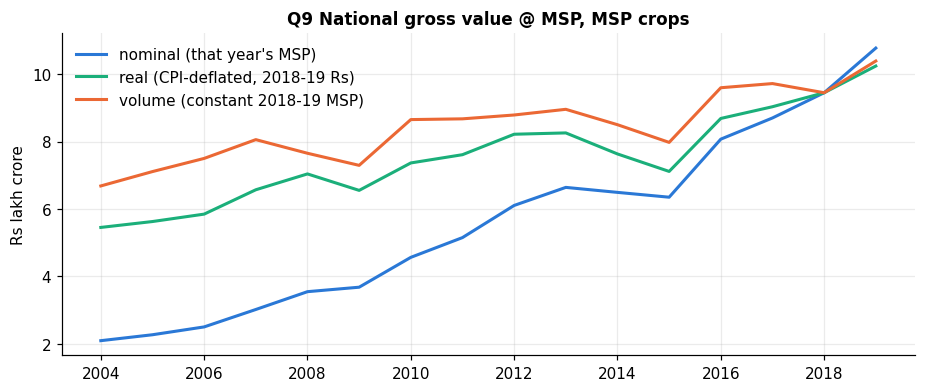

,crop_year,nominal,constant_2018_msp,real_cpi_2018,nominal_index_2004_100,volume_index_2004_100,real_index_2004_100
0,2004,209349.0,668402.0,545342.0,100.0,100.0,100.0
1,2005,226942.0,711022.0,562817.0,108.4,106.4,103.2
2,2006,250176.0,750064.0,584807.0,119.5,112.2,107.2
3,2007,301857.0,805802.0,657049.0,144.2,120.6,120.5
4,2008,354731.0,765367.0,704079.0,169.4,114.5,129.1
5,2009,367981.0,729484.0,655257.0,175.8,109.1,120.2
6,2010,456553.0,865272.0,736634.0,218.1,129.5,135.1
7,2011,515170.0,867485.0,761129.0,246.1,129.8,139.6
8,2012,610534.0,878909.0,821810.0,291.6,131.5,150.7
9,2013,664132.0,895745.0,825735.0,317.2,134.0,151.4


In [13]:
q9 = R["q09b_nominal_vs_volume"]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(q9.crop_year, q9.nominal / 1e5, color=BLUE, lw=2, label="nominal (that year's MSP)")
ax.plot(q9.crop_year, q9.real_cpi_2018 / 1e5, color=AQUA, lw=2, label="real (CPI-deflated, 2018-19 Rs)")
ax.plot(q9.crop_year, q9.constant_2018_msp / 1e5, color=ORANGE, lw=2, label="volume (constant 2018-19 MSP)")
ax.set_ylabel("Rs lakh crore"); ax.set_title("Q9 National gross value @ MSP, MSP crops"); ax.legend(frameon=False)
save(fig, "Q9_trend"); q9

Nominal ×4.5 from 2004-05 to 2018-19, real ×1.73 after CPI deflation, volume only ×1.41. Real ÷ volume ≈ 1.23, meaning MSPs rose about 23% faster than consumer prices. Dips in the 2014 and 2015 drought years.

### Did MSP rise after inflation?
Each crop's MSP deflated by CPI to constant 2018-19 rupees, 2004-05 vs 2024-25 (the last crop year with a CPI value for both calendar years).

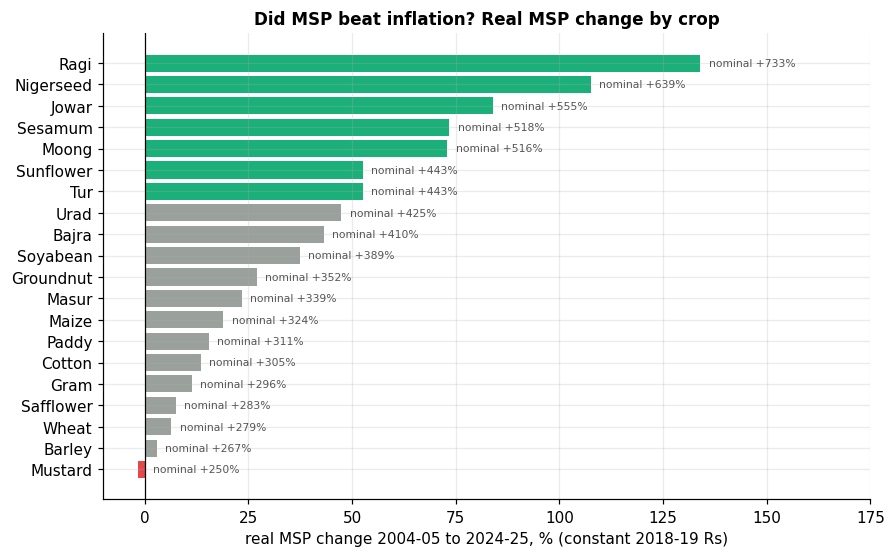

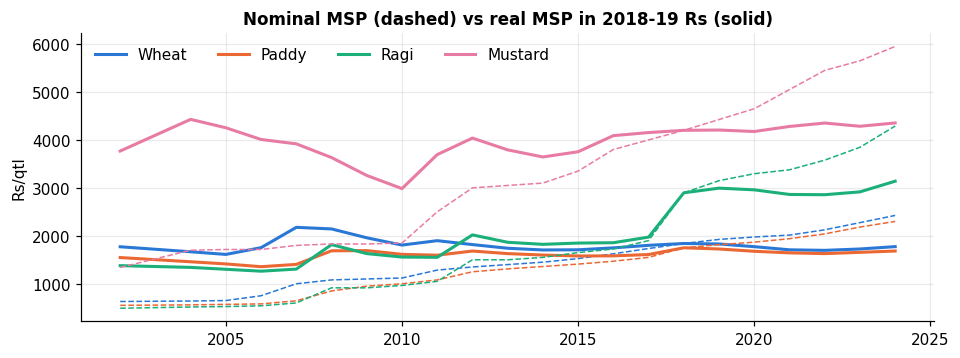

,msp_key,season,msp_2004,msp_2024,nominal_growth_pct,real_msp_2004,real_msp_2024,real_growth_pct,real_cagr_pct
12,Ragi,Kharif,515.0,4290.0,733.0,1341.5,3139.0,134.0,4.3
10,Nigerseed,Kharif,1180.0,8717.0,638.7,3073.8,6378.3,107.5,3.7
5,Jowar,Kharif,515.0,3371.0,554.6,1341.5,2466.6,83.9,3.1
14,Sesamum,Kharif,1500.0,9267.0,517.8,3907.4,6780.7,73.5,2.8
8,Moong,Kharif,1410.0,8682.0,515.7,3673.0,6352.7,73.0,2.8
17,Tur,Kharif,1390.0,7550.0,443.2,3620.9,5524.4,52.6,2.1
16,Sunflower,Kharif,1340.0,7280.0,443.3,3490.6,5326.8,52.6,2.1
18,Urad,Kharif,1410.0,7400.0,424.8,3673.0,5414.6,47.4,2.0
0,Bajra,Kharif,515.0,2625.0,409.7,1341.5,1920.7,43.2,1.8
15,Soyabean,Kharif,1000.0,4892.0,389.2,2604.9,3579.5,37.4,1.6


In [14]:
rm = R["q09c_real_msp_by_crop"].sort_values("real_growth_pct")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(rm.msp_key, rm.real_growth_pct, color=[AQUA if v > 50 else (RED if v < 0 else GREY) for v in rm.real_growth_pct])
for y, (r_, n_) in enumerate(zip(rm.real_growth_pct, rm.nominal_growth_pct)):
    ax.text(max(r_, 0) + 2, y, f"nominal +{n_:.0f}%", va="center", fontsize=7, color="#555")
ax.axvline(0, color="k", lw=.8); ax.set_xlim(-10, 175)
ax.set_xlabel("real MSP change 2004-05 to 2024-25, % (constant 2018-19 Rs)")
ax.set_title("Did MSP beat inflation? Real MSP change by crop")
save(fig, "Q9_real_msp")
s_ = R["q09d_real_msp_series"]
fig, ax = plt.subplots(figsize=(10, 3.4))
for k, c in [("Wheat", BLUE), ("Paddy", ORANGE), ("Ragi", AQUA), ("Mustard", PINK)]:
    t = s_[s_.msp_key == k]
    ax.plot(t.crop_year, t.msp_effective, color=c, lw=1, ls="--")
    ax.plot(t.crop_year, t.msp_real_2018, color=c, lw=2, label=k)
ax.set_ylabel("Rs/qtl"); ax.legend(frameon=False, ncol=4)
ax.set_title("Nominal MSP (dashed) vs real MSP in 2018-19 Rs (solid)"); plt.show()
rm.sort_values("real_growth_pct", ascending=False)

Nominal MSPs rose 250–730%, but after inflation the picture splits: **wheat +6%, paddy +15%, mustard −2%** in real terms over 20 years, while **ragi +134%, jowar +84%, moong +73%**. Real support for the two staple cereals barely moved, while millets and pulses were raised sharply, in line with the crop-diversification push.

## Q10. Which markets show large price variation?
Recent window: CV of daily modal price per market (>= 30 trading days, Jul–Sep 2026).

In [15]:
display(R["q11e_volatility_by_crop_2026"].head(8))
R["q11d_market_volatility_2026"].head(10)

,crop_name,markets,median_cv_pct
7,Onion,192,21.8
8,Potato,176,7.5
11,Soyabean,7,6.8
1,Bajra,1,5.5
12,Urad,1,5.2
3,Groundnut,41,5.0
6,Moong,1,4.4
5,Maize,9,3.2


,state_name,market_name,crop_name,price_form,trading_days,mean_modal,cv_pct,max_min_ratio
195,Tamil Nadu,Keelpennathur(Uzhavar Sandhai ),Onion,Onion,32,4227,36.0,2.60
67,Rajasthan,Sriganganagar (F&V) Apmc,Onion,Onion,30,3330,34.7,2.78
112,Tamil Nadu,Chinnamanur(Uzhavar Sandhai ),Potato,Potato,38,3866,33.2,2.32
36,Kerala,Chengannur Market,Onion,Onion,30,6055,33.1,3.33
40,Kerala,Palakkad Market,Onion,Onion,30,6987,33.0,3.14
464,Uttar Pradesh,Varanasi Apmc,Onion,Onion,31,2753,32.6,2.23
467,Uttarakhand,Haldwani Apmc,Onion,Onion,30,2687,32.2,2.71
381,Tamil Nadu,Tirupatthur(Uzhavar Sandhai ),Onion,Onion,38,5026,31.8,2.30
124,Tamil Nadu,Devakottai (Uzhavar Sandhai ),Onion,Onion,38,4832,31.6,2.44
364,Tamil Nadu,Theni(Uzhavar Sandhai ),Potato,Potato,35,3154,31.0,2.12


Longer window: monthly prices across Maharashtra APMCs, 2014-16.

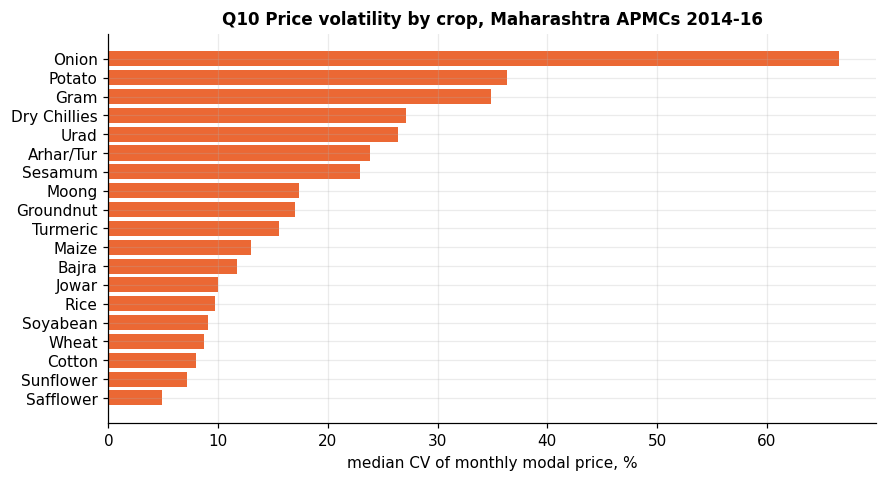

,state_name,market_name,crop_name,price_form,months,mean_modal,cv_pct,max_min_ratio,median_intramonth_spread_pct,mean_abs_mom_change_pct
506,Maharashtra,Kurdwadi-Modnimb,Onion,Onion,22,1011,86.6,9.45,142.7,27.2
19,Maharashtra,Ahmednagar,Onion,Onion,21,1473,81.2,8.62,138.6,29.9
518,Maharashtra,Lasalgaon-Niphad,Onion,Onion,23,1368,79.4,12.06,63.6,28.2
529,Maharashtra,Lasur Station,Onion,Onion,26,1145,79.2,12.78,132.8,25.9
582,Maharashtra,Malkapur,Onion,Onion,25,1223,78.0,14.13,64.3,29.4
819,Maharashtra,Rahuri-Vambori,Onion,Onion,27,1219,74.6,8.51,142.3,23.1
420,Maharashtra,Kalvan,Onion,Onion,26,1443,74.2,10.17,95.6,22.6
687,Maharashtra,Nandurbar,Dry Chillies,Dry red chillies,19,4097,73.5,5.74,39.4,38.3
771,Maharashtra,Pimpalgaon (B)-Saykheda,Onion,Onion,27,1176,73.3,12.63,94.3,23.4
51,Maharashtra,Akole,Onion,Onion,27,1252,73.1,8.32,145.9,24.0


In [16]:
q10 = R["q10b_volatility_by_crop_mh"]
fig, ax = plt.subplots(figsize=(9, 4.6))
d = q10[q10.markets >= 5].sort_values("median_cv_pct")
ax.barh(d.crop_name, d.median_cv_pct, color=ORANGE)
ax.set_xlabel("median CV of monthly modal price, %"); ax.set_title("Q10 Price volatility by crop, Maharashtra APMCs 2014-16")
save(fig, "Q10_volatility"); R["q10a_market_volatility_mh"].head(12)

## The same questions in SQL
`sql/analysis_queries.sql` has 15 queries: filtering, GROUP BY / HAVING, INNER and LEFT JOIN, CASE, CTEs and window functions (RANK, ROW_NUMBER, NTILE, LAG, FIRST_VALUE, SUM OVER, rolling AVG). Run them here and compare results with the Python analysis.

In [17]:
from src import sql_queries
S = sql_queries.main()
display(S["q09_value_over_time"].tail(6))
chk = S["q07_rain_yield_correlation"].set_index("crop_name").pearson_r.rename("sql").to_frame().join(
      R["q07a_rain_yield_association"].set_index("crop_name").pearson_r.rename("python"))
print("max |SQL - Python| for Pearson r:", round((chk.sql - chk.python).abs().max(), 4))
S["q03_best_district_per_state"].head(9)

q01_top_crops_by_gross_value                  22 rows
q02_profit_per_ha_where_cost_exists           10 rows
q03_best_district_per_state                   63 rows
q04_yield_quartiles_vs_value                  32 rows


q05_cross_market_dispersion_2026              18 rows
q06_msp_gap_by_month_2026                     54 rows
q07_rain_yield_correlation                    26 rows
q08_footprint_vs_profitability                22 rows
q09_value_over_time                           16 rows


q10_most_volatile_markets_2026                53 rows
q11_state_production_yoy                      38 rows
q12_real_msp_vs_inflation                     20 rows
q13_rolling_yield                            110 rows
q14_data_coverage_audit                       26 rows
q15_season_2026_outlook                       19 rows


,crop_year,crop_year_label,is_provisional,nominal_cr,real_2018_cr,volume_2018_msp_cr,nominal_yoy_pct,real_yoy_pct,nominal_index,real_index,volume_index
10,2014,2014-15,0,649314.0,763358.0,850094.0,-2.2,-7.6,310.2,140.0,127.2
11,2015,2015-16,0,635000.0,711468.0,797639.0,-2.2,-6.8,303.3,130.5,119.3
12,2016,2016-17,0,807218.0,868648.0,959764.0,27.1,22.1,385.6,159.3,143.6
13,2017,2017-18,0,870079.0,903422.0,972121.0,7.8,4.0,415.6,165.7,145.4
14,2018,2018-19,0,944903.0,944903.0,944903.0,8.6,4.6,451.4,173.3,141.4
15,2019,2019-20,1,1077430.0,1024145.0,1038998.0,14.0,8.4,514.7,187.8,155.4


max |SQL - Python| for Pearson r: 0.0


,state_rank,state_name,state_value_per_ha,rank_in_state,district_name,district_value_per_ha,pct_above_state_avg
0,1,Punjab,83126.0,1,Fatehgarh Sahib,91701.0,10.3
1,1,Punjab,83126.0,2,Ludhiana,90809.0,9.2
2,1,Punjab,83126.0,3,Sangrur,90522.0,8.9
3,2,Tamil Nadu,68444.0,1,Erode,116253.0,69.8
4,2,Tamil Nadu,68444.0,2,Villupuram,108562.0,58.6
5,2,Tamil Nadu,68444.0,3,Kanchipuram,94995.0,38.8
6,3,Haryana,68087.0,1,Yamunanagar,92612.0,36.0
7,3,Haryana,68087.0,2,Kurukshetra,86300.0,26.7
8,3,Haryana,68087.0,3,Ambala,81869.0,20.2


**Which states had the highest year-on-year production growth?** (LAG per state, HAVING, RANK, CASE)

In [18]:
S["q11_state_production_yoy"].head(10)

,crop_name,state_name,production_2017_mt,production_2018_mt,yoy_growth_pct,growth_rank,trend
0,Rice,Madhya Pradesh,4.27,5.24,22.6,1,strong growth (>=10%)
1,Rice,Maharashtra,2.73,3.28,20.0,2,strong growth (>=10%)
2,Rice,Karnataka,2.91,3.46,19.1,3,strong growth (>=10%)
3,Rice,Odisha,6.55,7.73,18.0,4,strong growth (>=10%)
4,Rice,Punjab,10.51,12.26,16.6,5,strong growth (>=10%)
5,Rice,Chhattisgarh,5.75,6.51,13.2,6,strong growth (>=10%)
6,Rice,Kerala,0.52,0.58,10.9,7,strong growth (>=10%)
7,Rice,Telangana,6.26,6.67,6.5,8,growth
8,Rice,Uttar Pradesh,15.52,16.02,3.2,9,growth
9,Rice,Assam,5.28,5.44,2.9,10,growth


**What can each crop be analysed for?** LEFT JOIN keeps crops with no MSP or no cost data visible.

In [19]:
S["q14_data_coverage_audit"]

,crop_name,crop_group,msp_years,first_msp,last_msp,mandi_quotes,msp_comparable_quotes,cost_state_years,analysis_scope
0,Dry Chillies,Spices,0,NaN,NaN,717,0,0,no MSP: price analysis only
1,Onion,Horticulture,0,NaN,NaN,16653,0,0,no MSP: price analysis only
2,Potato,Horticulture,0,NaN,NaN,15111,0,0,no MSP: price analysis only
3,Turmeric,Spices,0,NaN,NaN,520,0,0,no MSP: price analysis only
4,Arhar/Tur,Pulses,24,2002.0,2026.0,4567,4567,30,valued and profit-estimated
5,Cotton,Fibres,24,2002.0,2026.0,2119,2012,30,valued and profit-estimated
6,Gram,Pulses,24,2002.0,2026.0,6642,6447,30,valued and profit-estimated
7,Groundnut,Oilseeds,24,2002.0,2026.0,4184,4172,30,valued and profit-estimated
8,Maize,Cereals,24,2002.0,2026.0,6177,6176,30,valued and profit-estimated
9,Moong,Pulses,24,2002.0,2026.0,4167,4162,30,valued and profit-estimated


**3-year rolling average yield** (AVG OVER ROWS BETWEEN 2 PRECEDING AND CURRENT ROW)

In [20]:
S["q13_rolling_yield"].query("crop_name == 'Wheat'").tail(8)

,crop_name,crop_year,yield_t_per_ha,yield_3yr_avg,vs_prev_3yr_avg_pct
102,Wheat,2011,3.260,3.068,10.4
103,Wheat,2012,3.315,3.226,8.0
104,Wheat,2013,3.237,3.271,0.3
105,Wheat,2014,2.726,3.093,-16.6
106,Wheat,2015,3.113,3.025,0.7
107,Wheat,2016,3.547,3.129,17.2
108,Wheat,2017,3.618,3.426,15.6
109,Wheat,2018,3.621,3.596,5.7


## Summary
See `outputs/results/findings.md` for the auto-generated headline numbers and `docs/METHODOLOGY.md` for assumptions and limitations.

## Conclusion
Gross value is driven by MSP more than volume; real MSP support for wheat and paddy barely rose; many crops trade below MSP, more so against the 2026-27 MSP.

## Limitations
Gross value is an estimate at MSP, not income; profit only where DES cost exists; rainfall results are associations; 2026 prices are pre-harvest.

## Next steps
Re-run the 2026 outlook with harvest-season prices (Oct-Dec 2026).